# Lab Assignment 1: Artificial Neural Networks
**Course:** Foundations of Neural Networks and Deep Learning  
**Implementation:** Python, TensorFlow/Keras. All five questions and their subparts are covered below.

Run all cells in order. The first execution downloads CIFAR-10, California Housing and MNIST.
The notebook uses the complete datasets, fixed splits and seed 42. Each experiment reports actual
measurements from its execution; no performance numbers are hard-coded. CPU execution can take several minutes.
The four truth-table rows are the complete logical domain, so Q1 evaluates memorization of that domain.
For Q2-Q5, preprocessing is fitted on training data only and validation data controls model selection.
Test scores in comparison tables are required by the assignment and are descriptive; they do not select models.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['KERAS_HOME'] = str(__import__('pathlib').Path('.cache/keras').resolve())
import json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from IPython.display import display, Markdown
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
OUT = Path('results'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Python', platform.python_version(), '| TensorFlow', tf.__version__)
print('Devices:', tf.config.list_physical_devices())

def reset():
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

def dataset(x, y, training=False, batch=256):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(batch).with_options(options).prefetch(1)

def fit(model, x, y, xv, yv, epochs=30, patience=5, batch=256):
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                        min_delta=1e-4, restore_best_weights=True)
    history = model.fit(dataset(x,y,True,batch), validation_data=dataset(xv,yv,batch=batch),
                        epochs=epochs, callbacks=[stop], verbose=0)
    print(f'{model.name}: {len(history.epoch)} epochs; best validation loss '
          f'{min(history.history["val_loss"]):.4f}')
    return history, stop

def predict(model, x):
    return model.predict(dataset(x, np.zeros(len(x))), verbose=0)

def saveplot(name):
    plt.tight_layout(); plt.savefig(OUT / f'{name}.png', bbox_inches='tight'); plt.show()

def curves(history, name, classification=True):
    keys = ['loss', 'accuracy'] if classification else ['loss', 'mae']
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    for ax,key in zip(axes,keys):
        ax.plot(np.arange(1,len(history.epoch)+1),history.history[key],label='Training')
        ax.plot(np.arange(1,len(history.epoch)+1),history.history['val_'+key],label='Validation')
        ax.set(xlabel='Epoch',ylabel=key, title=name+' '+key); ax.legend(); ax.grid(alpha=.2)
    saveplot(name+'_curves')

def table(frame, name):
    display(frame); frame.to_csv(OUT / f'{name}.csv', index=False)

def classification_report_row(model, x, y):
    probability = predict(model,x).ravel(); predicted = (probability >= .5).astype(int)
    return dict(accuracy=accuracy_score(y,predicted),precision=precision_score(y,predicted),
                recall=recall_score(y,predicted),f1=f1_score(y,predicted)), predicted

def gap_note(history):
    i = int(np.argmin(history.history['val_loss']))
    gap = history.history['accuracy'][i] - history.history['val_accuracy'][i]
    display(Markdown(f'At the minimum-validation-loss epoch ({i+1}), training accuracy is '
        f'{history.history["accuracy"][i]:.3f}, validation accuracy is '
        f'{history.history["val_accuracy"][i]:.3f}, and the gap is {gap:.3f}. '
        + ('The positive gap suggests overfitting; dropout or stronger L2 is a reasonable next experiment.'
           if gap > .05 else 'There is no large positive accuracy gap at this checkpoint. '
           'Low accuracy on both splits would instead suggest underfitting. '
           'More representative data and validation-guided capacity changes can improve generalization.')))

Python 3.11.9 | TensorFlow 2.18.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## Q1. AND, OR and XOR with ANN (a-f)
Inputs are already in [0,1]. AND and OR use a single trainable layer: one sigmoid neuron,
binary cross-entropy (BCE) and Adam with learning rate 0.05. Sigmoid plus threshold 0.5 implements
a perceptron decision boundary while retaining differentiable training. BCE is appropriate for Bernoulli targets.
The small learning task allows a larger step than the image experiments.

XOR uses the same single-layer baseline and a 2-4-1 multilayer network with tanh hidden neurons.
Four hidden neurons provide enough nonlinear features; tanh is smooth and permits signed intermediate values.
For XOR a line would require b < 0, w1+b > 0, w2+b > 0, and w1+w2+b < 0.
The middle inequalities imply w1+w2+b > -b > 0, contradicting the last inequality.
Thus no single-layer linear decision boundary can classify all four XOR inputs.

,x1,x2,AND,OR,XOR
0,0.0,0.0,0,0,0
1,0.0,1.0,0,1,1
2,1.0,0.0,0,1,1
3,1.0,1.0,1,1,0


,model,x1,x2,expected,probability,predicted
0,AND,0,0,0,7.314859e-07,0
1,AND,0,1,0,8.539953e-03,0
2,AND,1,0,0,8.527027e-03,0
3,AND,1,1,1,9.902222e-01,1
4,OR,0,0,0,3.439746e-03,0
5,OR,0,1,1,9.982213e-01,1
6,OR,1,0,1,9.987273e-01,1
7,OR,1,1,1,1.000000e+00,1
8,XOR single layer,0,0,0,5.000001e-01,1
9,XOR single layer,0,1,1,5.000001e-01,1


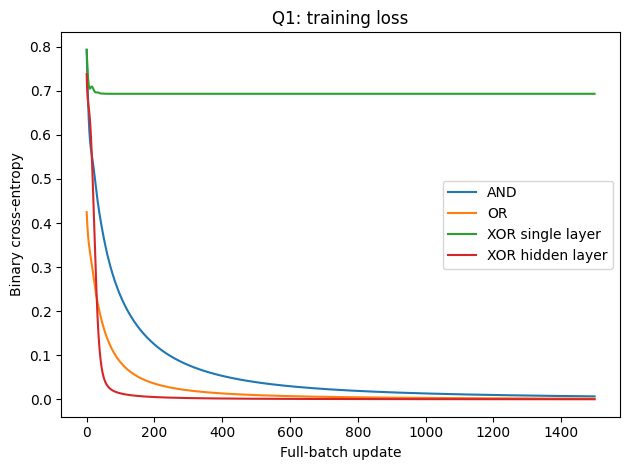

**Observation:** AND, OR and the hidden-layer XOR network classify all four rows correctly. The single-layer XOR network fails on at least one row. Its loss plateaus because the representation is insufficient, whereas the nonlinear hidden layer can combine multiple boundaries. These are exhaustive truth-table checks, not evidence of generalization to a separate dataset.

In [2]:
logic_x = np.array([[0,0],[0,1],[1,0],[1,1]], dtype='float32')
targets = {'AND': np.array([0,0,0,1]), 'OR': np.array([0,1,1,1]),
           'XOR single layer': np.array([0,1,1,0]), 'XOR hidden layer': np.array([0,1,1,0])}
display(pd.DataFrame({'x1':logic_x[:,0], 'x2':logic_x[:,1],
                      'AND':targets['AND'], 'OR':targets['OR'], 'XOR':targets['XOR single layer']}))
logic_rows=[]; logic_losses={}
for name, target in targets.items():
    reset()
    layers = [keras.Input((2,))]
    if name == 'XOR hidden layer': layers += [keras.layers.Dense(4,activation='tanh')]
    model = keras.Sequential(layers+[keras.layers.Dense(1,activation='sigmoid')])
    model.compile(optimizer=keras.optimizers.Adam(.05),loss='binary_crossentropy')
    losses=[]
    @tf.function
    def logic_step():
        with tf.GradientTape() as tape:
            loss = keras.losses.binary_crossentropy(target.astype('float32').reshape(-1,1), model(logic_x, training=True))
            loss = tf.reduce_mean(loss)
        model.optimizer.apply_gradients(zip(tape.gradient(loss,model.trainable_weights), model.trainable_weights))
        return loss
    for epoch in range(1500): losses.append(float(logic_step()))
    probabilities = model(logic_x,training=False).numpy().ravel()
    predictions=(probabilities>=.5).astype(int)
    for x,y,p,yp in zip(logic_x,target,probabilities,predictions):
        logic_rows.append(dict(model=name,x1=int(x[0]),x2=int(x[1]),expected=y,
                               probability=float(p),predicted=yp))
    logic_losses[name]=losses
    if name in ['AND','OR','XOR hidden layer']: assert np.array_equal(predictions,target)
    else: assert not np.array_equal(predictions,target)
logic_table=pd.DataFrame(logic_rows); table(logic_table,'q1_predictions')
for name,losses in logic_losses.items(): plt.plot(losses,label=name)
plt.xlabel('Full-batch update'); plt.ylabel('Binary cross-entropy'); plt.legend()
plt.title('Q1: training loss'); saveplot('q1_loss')
display(Markdown('**Observation:** AND, OR and the hidden-layer XOR network classify all four rows correctly. '
    'The single-layer XOR network fails on at least one row. Its loss plateaus because the representation is '
    'insufficient, whereas the nonlinear hidden layer can combine multiple boundaries. '
    'These are exhaustive truth-table checks, not evidence of generalization to a separate dataset.'))

## Q2. Breast Cancer Wisconsin Diagnostic (a-f)
The 30 numeric predictors describe cell nuclei. We explicitly recode **malignant as 1** and benign as 0,
so precision/recall/F1 refer to the malignant class. An 80/20 stratified train/test split preserves class proportions;
20% of the training partition is reserved for validation. StandardScaler is fitted only on the remaining training rows.
Scaling prevents large-magnitude measurements from dominating gradients and improves optimizer conditioning.

Architecture: 30-32-16-1, ReLU hidden layers, sigmoid output. This modest capacity models interactions
without a large parameter budget for 569 samples. Adam(0.001) is a practical adaptive optimizer;
BCE matches the binary target. Early stopping restores minimum-validation-loss weights.

Feature shape: (569, 30) | target shape: (569,)


,feature,dtype,missing
0,mean radius,float64,0
1,mean texture,float64,0
2,mean perimeter,float64,0
3,mean area,float64,0
4,mean smoothness,float64,0
5,mean compactness,float64,0
6,mean concavity,float64,0
7,mean concave points,float64,0
8,mean symmetry,float64,0
9,mean fractal dimension,float64,0


Duplicate feature rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Classes (0=benign, 1=malignant):


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

breast_cancer: 43 epochs; best validation loss 0.0830


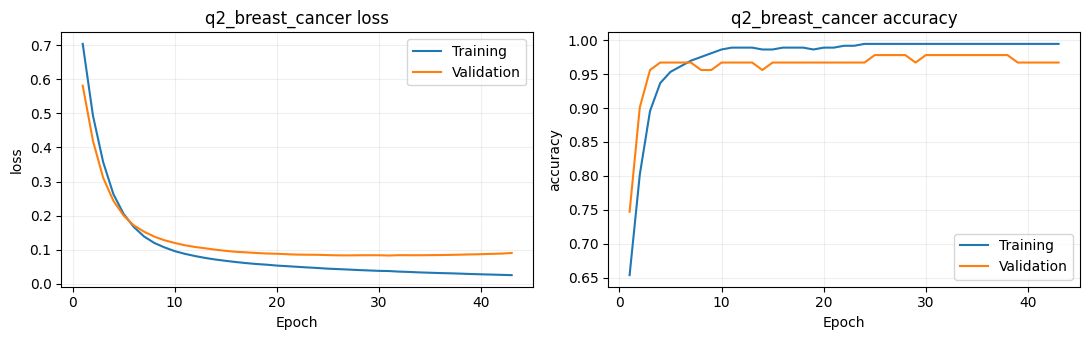

,accuracy,precision,recall,f1
0,0.973684,1.0,0.928571,0.962963


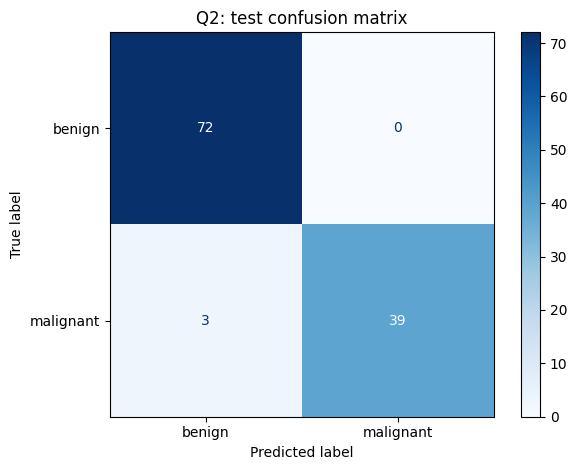

At the minimum-validation-loss epoch (31), training accuracy is 0.995, validation accuracy is 0.978, and the gap is 0.016. There is no large positive accuracy gap at this checkpoint. Low accuracy on both splits would instead suggest underfitting. More representative data and validation-guided capacity changes can improve generalization.

In [3]:
bc = load_breast_cancer(as_frame=True)
features = bc.data.copy(); target = (bc.target == 0).astype('int32')
print('Feature shape:',features.shape, '| target shape:',target.shape)
table(pd.DataFrame({'feature':features.columns,'dtype':features.dtypes.astype(str).values,
                    'missing':features.isna().sum().values}), 'q2_feature_audit')
print('Duplicate feature rows:',features.duplicated().sum())
display(features.describe().T)
print('Classes (0=benign, 1=malignant):'); display(target.value_counts().sort_index())
X_pool,X_test,y_pool,y_test = train_test_split(features,target,test_size=.2,stratify=target,random_state=SEED)
X_train,X_val,y_train,y_val = train_test_split(X_pool,y_pool,test_size=.2,stratify=y_pool,random_state=SEED)
bc_scaler=StandardScaler().fit(X_train)
X_train,X_val,X_test=[bc_scaler.transform(x).astype('float32') for x in [X_train,X_val,X_test]]
print('Train/validation/test:',len(X_train),len(X_val),len(X_test))
reset()
bc_model=keras.Sequential([keras.Input((30,)),keras.layers.Dense(32,activation='relu'),
    keras.layers.Dense(16,activation='relu'),keras.layers.Dense(1,activation='sigmoid')],name='breast_cancer')
bc_model.compile(optimizer=keras.optimizers.Adam(.001),loss='binary_crossentropy',metrics=['accuracy'])
bc_model.summary()
bc_history,_=fit(bc_model,X_train,y_train,X_val,y_val,epochs=120,patience=12,batch=32)
curves(bc_history,'q2_breast_cancer')
bc_metrics,bc_pred=classification_report_row(bc_model,X_test,y_test)
table(pd.DataFrame([bc_metrics]),'q2_test_metrics')
ConfusionMatrixDisplay.from_predictions(y_test,bc_pred,display_labels=['benign','malignant'],cmap='Blues')
plt.title('Q2: test confusion matrix'); saveplot('q2_confusion')
gap_note(bc_history)

## Q3. Fully connected CIFAR-10 classification (a-f)
CIFAR-10 has 50,000 training and 10,000 test RGB images of size 32x32. We reserve 10,000 of the original
training images for stratified validation and use all remaining 40,000 for fitting. Dividing by 255 puts pixels
in [0,1]; Flatten converts each image into 3,072 features. This bounds gradient scales while preserving color values.

Both networks use Flatten-256(ReLU)-128(ReLU)-10(softmax). Two hidden layers learn nonlinear combinations;
ReLU avoids the positive-side saturation of sigmoid. Softmax gives ten mutually exclusive class probabilities.
Sparse categorical cross-entropy uses integer class labels. Adam(0.001), batch 256, maximum 20 epochs
and identical splits/seeds make the comparison controlled. The second network adds dropout 0.3 after
each hidden layer, discouraging reliance on a few activations. No convolution layers are used.

Original dimensions: (50000, 32, 32, 3) (50000,) (10000, 32, 32, 3) (10000,)


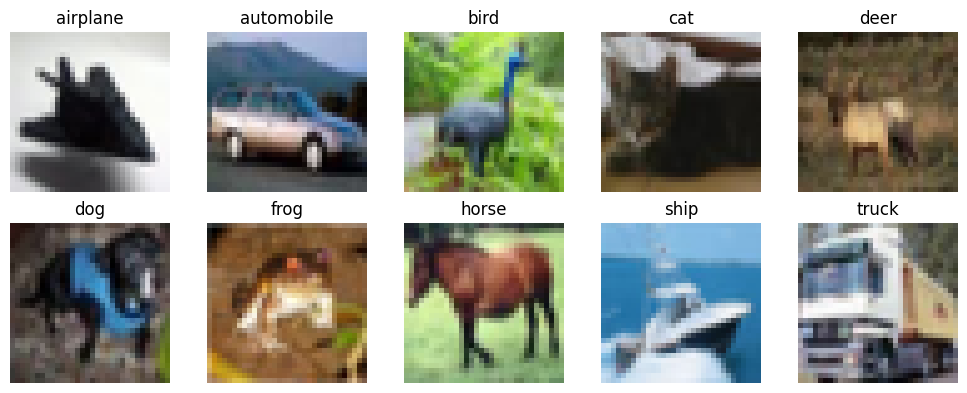

Flattened input width: 3072 | normalized range: 0.0 1.0


Model: "cifar_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

cifar_baseline: 20 epochs; best validation loss 1.4350


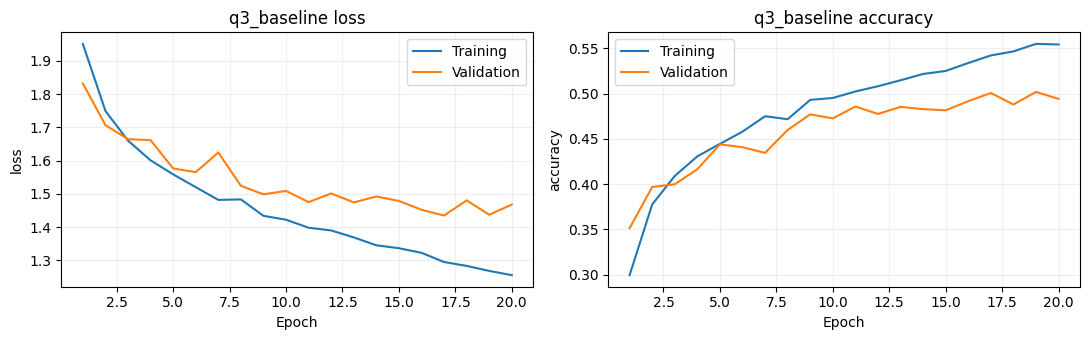

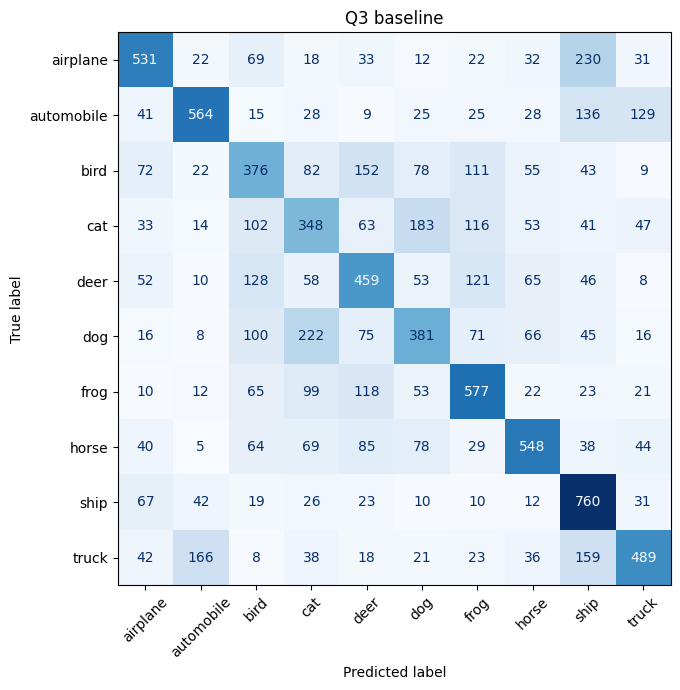

,actual,predicted,count
0,airplane,ship,230
1,dog,cat,222
2,cat,dog,183
3,truck,automobile,166
4,truck,ship,159


At the minimum-validation-loss epoch (17), training accuracy is 0.542, validation accuracy is 0.501, and the gap is 0.041. There is no large positive accuracy gap at this checkpoint. Low accuracy on both splits would instead suggest underfitting. More representative data and validation-guided capacity changes can improve generalization.

Model: "cifar_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

cifar_dropout: 20 epochs; best validation loss 1.6005


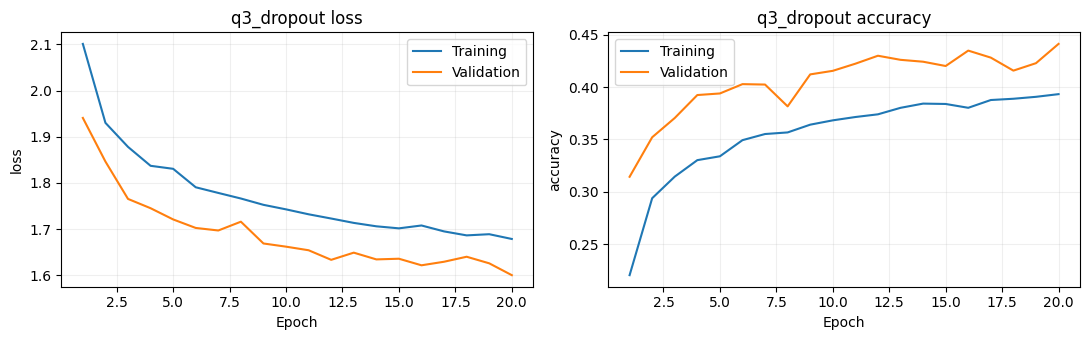

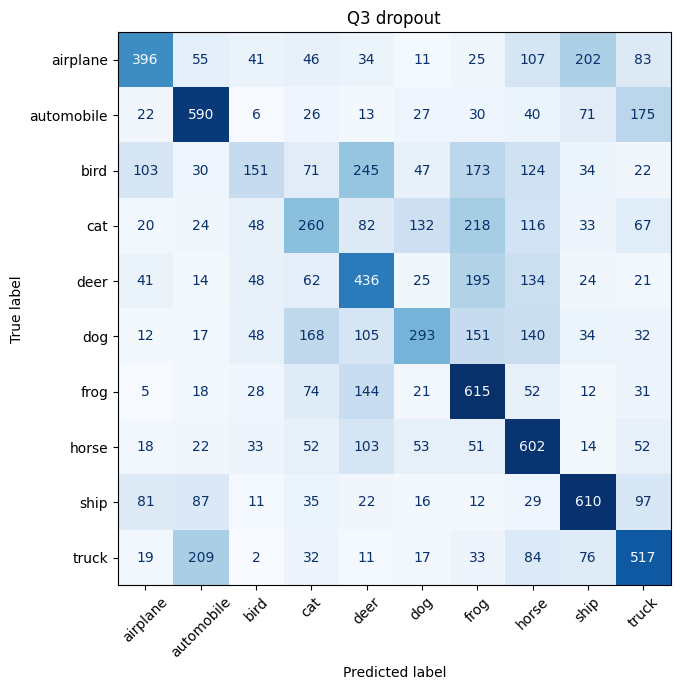

,actual,predicted,count
0,bird,deer,245
1,cat,frog,218
2,truck,automobile,209
3,airplane,ship,202
4,deer,frog,195


At the minimum-validation-loss epoch (20), training accuracy is 0.393, validation accuracy is 0.441, and the gap is -0.048. There is no large positive accuracy gap at this checkpoint. Low accuracy on both splits would instead suggest underfitting. More representative data and validation-guided capacity changes can improve generalization.

,model,epochs,train_accuracy,validation_loss,validation_accuracy,test_accuracy
0,baseline,20,0.557850,1.435009,0.5006,0.5033
1,dropout,20,0.458175,1.600521,0.4412,0.4470


**Comparison:** select **baseline** by validation loss (1.4350). Compare the table and curves for the measured regularization effect; dropout can reduce the train-validation gap but can also underfit with this short budget. Dense networks discard spatial locality, limiting image accuracy. A CNN would be a sensible future extension, outside the required fully connected architecture.

In [4]:
(cx,cy),(cx_test,cy_test)=keras.datasets.cifar10.load_data()
cy=cy.ravel(); cy_test=cy_test.ravel()
class_names=np.array(['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck'])
print('Original dimensions:',cx.shape,cy.shape,cx_test.shape,cy_test.shape)
fig,axes=plt.subplots(2,5,figsize=(10,4))
for label,ax in enumerate(axes.ravel()):
    i=np.flatnonzero(cy==label)[0]; ax.imshow(cx[i]); ax.set_title(class_names[label]); ax.axis('off')
saveplot('q3_samples')
idx_tr,idx_val=train_test_split(np.arange(len(cx)),test_size=.2,stratify=cy,random_state=SEED)
cx_train,cx_val=cx[idx_tr].astype('float32')/255,cx[idx_val].astype('float32')/255
cy_train,cy_val=cy[idx_tr],cy[idx_val]
cx_test=cx_test.astype('float32')/255
del cx
print('Flattened input width:',np.prod(cx_train.shape[1:]), '| normalized range:',cx_train.min(),cx_train.max())
cifar_rows=[]; cifar_histories={}
for regularized in [False,True]:
    reset(); name='dropout' if regularized else 'baseline'
    layers=[keras.Input((32,32,3)),keras.layers.Flatten()]
    for width in [256,128]:
        layers.append(keras.layers.Dense(width,activation='relu'))
        if regularized: layers.append(keras.layers.Dropout(.3))
    model=keras.Sequential(layers+[keras.layers.Dense(10,activation='softmax')],name='cifar_'+name)
    model.compile(optimizer=keras.optimizers.Adam(.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    model.summary()
    hist,_=fit(model,cx_train,cy_train,cx_val,cy_val,epochs=20,patience=5)
    cifar_histories[name]=hist; curves(hist,'q3_'+name)
    test_pred=predict(model,cx_test).argmax(axis=1)
    train_score=model.evaluate(dataset(cx_train,cy_train),verbose=0)
    val_score=model.evaluate(dataset(cx_val,cy_val),verbose=0)
    cifar_rows.append(dict(model=name,epochs=len(hist.epoch),train_accuracy=train_score[1],
        validation_loss=val_score[0],validation_accuracy=val_score[1],test_accuracy=accuracy_score(cy_test,test_pred)))
    cm=confusion_matrix(cy_test,test_pred)
    fig,ax=plt.subplots(figsize=(8,7)); ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
    ax.set_title('Q3 '+name); saveplot('q3_'+name+'_confusion')
    np.fill_diagonal(cm,0)
    pairs=np.argsort(cm.ravel())[::-1][:5]
    table(pd.DataFrame([{'actual':class_names[i//10],'predicted':class_names[i%10],
                         'count':int(cm.ravel()[i])} for i in pairs]),'q3_'+name+'_confused_pairs')
    gap_note(hist)
cifar_results=pd.DataFrame(cifar_rows); table(cifar_results,'q3_comparison')
winner=cifar_results.loc[cifar_results.validation_loss.idxmin()]
display(Markdown(f'**Comparison:** select **{winner.model}** by validation loss ({winner.validation_loss:.4f}). '
    'Compare the table and curves for the measured regularization effect; dropout can reduce the train-validation '
    'gap but can also underfit with this short budget. Dense networks discard spatial locality, limiting image accuracy. '
    'A CNN would be a sensible future extension, outside the required fully connected architecture.'))
del cx_train,cx_val,cx_test

## Q4. Housing-price regression (a-f, including both final f items)
California Housing contains eight numerical predictors for census block groups; the target is median
house value in **$100,000 units**. There are no categorical columns in this dataset, so no artificial
categories are introduced. The preprocessing pipeline nevertheless handles categorical columns with
most-frequent imputation and one-hot encoding if present. Numeric columns use median imputation and
standardization fitted on training data. IQR flags describe possible outliers; they are not automatically
deleted, since extreme ratios may be real. Target values are capped near 5.0, a limitation of this dataset.

An 80/20 train/test split is followed by a validation split inside training. A 8-64-32-1 ANN uses ReLU
hidden neurons and one linear output because price is one continuous value, not a probability.
MSE penalizes large errors and provides a smooth training objective. Adam(0.001) is compared with
SGD(0.01, momentum=0.9) using the same initialization, data, batch size and stopping rule.
Both use gradient clipnorm 1.0 to limit unstable updates from extreme housing feature ratios.
This compares practical optimizer configurations, not an exhaustive optimizer tuning study.

Shape: (20640, 8) | target: MedHouseVal in $100,000
Numeric: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude'] | Categorical: []


,feature,missing,IQR_outlier_count
0,MedInc,0,681
1,HouseAge,0,0
2,AveRooms,0,511
3,AveBedrms,0,1424
4,Population,0,1196
5,AveOccup,0,711
6,Latitude,0,0
7,Longitude,0,0


Duplicate features: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

housing_Adam: 72 epochs; best validation loss 0.3023


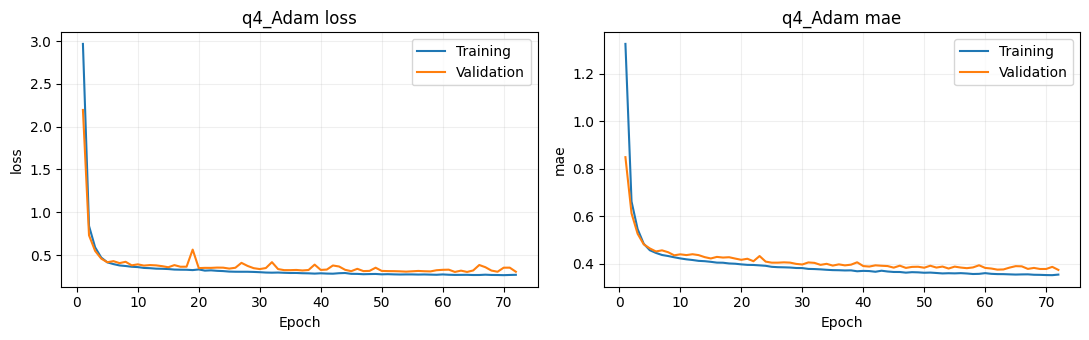

Model: "housing_SGD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

housing_SGD: 56 epochs; best validation loss 0.2988


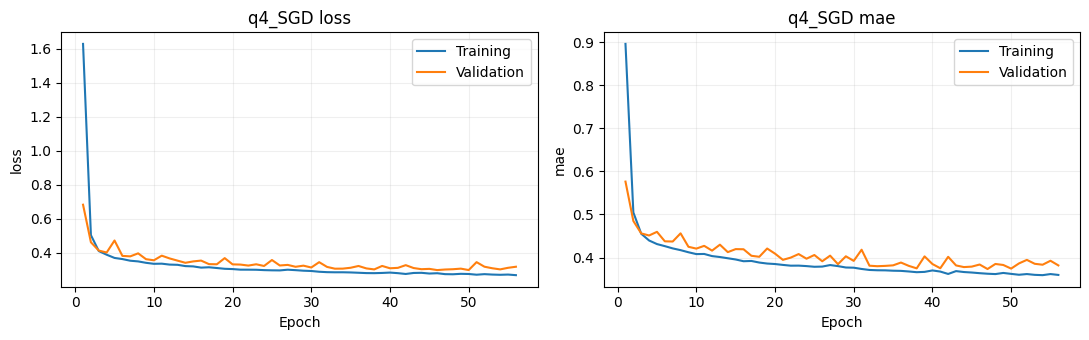

,optimizer,epochs,validation_mse,MAE,MSE,RMSE,R2
0,Adam,72,0.302352,0.365597,0.291118,0.539554,0.777842
1,SGD,56,0.298802,0.378559,0.298521,0.546371,0.772192


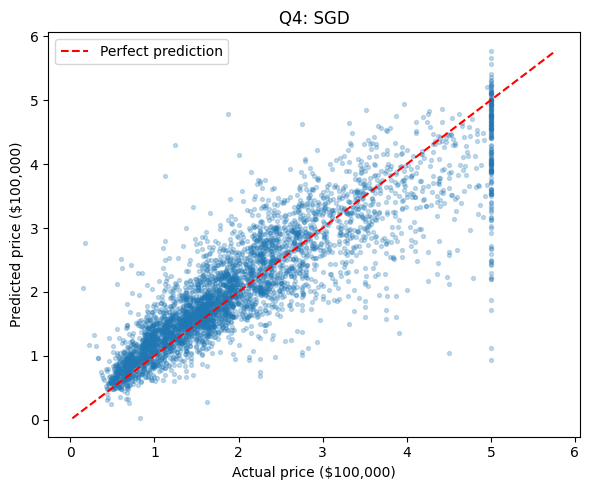

**Model for further testing: SGD.** It has the lower validation MSE (0.2988); held-out RMSE is 0.5464 in $100,000 units (approximately $54,637) and R² is 0.7722. At the best validation epoch 46, training MSE is 0.2803 and validation MSE is 0.2988. The training and validation errors are reasonably close; there is no strong gap-based evidence of overfitting. A rising validation loss with falling training loss indicates overfitting; persistently high losses on both splits suggest underfitting. Inspect the reported curves alongside these values. Early stopping already limits late overfitting; L2 and cross-validation are useful next checks. The capped target limits high-price predictions.

In [5]:
housing=fetch_california_housing(as_frame=True,data_home='.cache/sklearn')
hx=housing.data; hy=housing.target
print('Shape:',hx.shape,'| target:',hy.name,'in $100,000')
numeric=hx.select_dtypes(include=np.number).columns.tolist()
categorical=hx.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric:',numeric,'| Categorical:',categorical)
q1=hx[numeric].quantile(.25); q3=hx[numeric].quantile(.75); iqr=q3-q1
table(pd.DataFrame({'feature':hx.columns,'missing':hx.isna().sum().values,
    'IQR_outlier_count':((hx[numeric] < q1-1.5*iqr)|(hx[numeric] > q3+1.5*iqr)).sum().values}), 'q4_audit')
print('Duplicate features:',hx.duplicated().sum()); display(hx.describe().T); display(hy.describe())
hx_pool,hx_test,hy_pool,hy_test=train_test_split(hx,hy,test_size=.2,random_state=SEED)
hx_train,hx_val,hy_train,hy_val=train_test_split(hx_pool,hy_pool,test_size=.2,random_state=SEED)
preprocessor=ColumnTransformer([
    ('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numeric),
    ('categorical',make_pipeline(SimpleImputer(strategy='most_frequent'),
                                OneHotEncoder(handle_unknown='ignore',sparse_output=False)),categorical)])
hx_train=preprocessor.fit_transform(hx_train).astype('float32')
hx_val=preprocessor.transform(hx_val).astype('float32'); hx_test=preprocessor.transform(hx_test).astype('float32')
housing_models={}; housing_histories={}; housing_rows=[]
for name in ['Adam','SGD']:
    reset()
    model=keras.Sequential([keras.Input((hx_train.shape[1],)),keras.layers.Dense(64,activation='relu'),
        keras.layers.Dense(32,activation='relu'),keras.layers.Dense(1)],name='housing_'+name)
    optimizer=keras.optimizers.Adam(.001,clipnorm=1.0) if name=='Adam' else keras.optimizers.SGD(.01,momentum=.9,clipnorm=1.0)
    model.compile(optimizer=optimizer,loss='mse',metrics=['mae'])
    model.summary()
    hist,_=fit(model,hx_train,hy_train,hx_val,hy_val,epochs=100,patience=10)
    curves(hist,'q4_'+name,classification=False)
    pred=predict(model,hx_test).ravel()
    row=dict(optimizer=name,epochs=len(hist.epoch),validation_mse=model.evaluate(dataset(hx_val,hy_val),verbose=0)[0],
        MAE=mean_absolute_error(hy_test,pred),MSE=mean_squared_error(hy_test,pred),
        RMSE=np.sqrt(mean_squared_error(hy_test,pred)),R2=r2_score(hy_test,pred))
    housing_rows.append(row); housing_models[name]=model; housing_histories[name]=hist
housing_results=pd.DataFrame(housing_rows); table(housing_results,'q4_optimizer_comparison')
selected=housing_results.loc[housing_results.validation_mse.idxmin()]
best_housing=housing_models[selected.optimizer]; hp=predict(best_housing,hx_test).ravel()
plt.figure(figsize=(6,5)); plt.scatter(hy_test,hp,s=8,alpha=.25)
limits=[min(hy_test.min(),hp.min()),max(hy_test.max(),hp.max())]
plt.plot(limits,limits,'r--',label='Perfect prediction'); plt.legend()
plt.xlabel('Actual price ($100,000)'); plt.ylabel('Predicted price ($100,000)')
plt.title('Q4: '+selected.optimizer); saveplot('q4_actual_predicted')
hist=housing_histories[selected.optimizer]; best_epoch=int(np.argmin(hist.history['val_loss']))
train_mse=hist.history['loss'][best_epoch]; val_mse=hist.history['val_loss'][best_epoch]
diagnosis=('The validation error is substantially higher than training error, suggesting overfitting.'
    if val_mse > train_mse*1.25 else
    'The training and validation errors are reasonably close; there is no strong gap-based evidence of overfitting.')
display(Markdown(f'**Model for further testing: {selected.optimizer}.** It has the lower validation MSE '
    f'({selected.validation_mse:.4f}); held-out RMSE is {selected.RMSE:.4f} in $100,000 units '
    f'(approximately ${selected.RMSE*100000:,.0f}) and R² is {selected.R2:.4f}. '
    f'At the best validation epoch {best_epoch+1}, training MSE is {hist.history["loss"][best_epoch]:.4f} '
    f'and validation MSE is {hist.history["val_loss"][best_epoch]:.4f}. '
    + diagnosis + ' A rising validation loss with falling training loss indicates overfitting; persistently high losses on both '
    'splits suggest underfitting. Inspect the reported curves alongside these values. Early stopping already limits '
    'late overfitting; L2 and cross-validation are useful next checks. The capped target limits high-price predictions.'))

## Q5. MNIST hyperparameters and regularization (a-e)
MNIST Digits is the permitted dataset choice. All 60,000 original training examples are split into
48,000 training and 12,000 stratified validation examples; the official 10,000 test examples remain separate.
Pixels are normalized to [0,1]. Each model uses Flatten-**n**(ReLU)-10(softmax), sparse categorical
cross-entropy and batch 256. One factor changes at a time from the 64-neuron Adam(0.001) baseline.

Experiments cover widths 16/32/64/128; learning rates 0.001/0.01/0.1; SGD/RMSprop/Adam;
and none/dropout(0.3)/L2(0.0001)/both. SGD uses momentum 0.9 and the same 0.001 learning rate
as the other optimizers, so slower progress within the finite budget is possible. L2 penalizes large weights;
dropout randomly disables hidden units only during training. Early stopping monitors validation loss with
patience 3, min_delta 0.0001 and restored best weights. All runs have the same 15-epoch maximum.
L2 validation losses include the penalty, so choose the overall model by validation accuracy instead.
Training accuracy below is re-evaluated at inference time to make dropout comparisons fair.

MNIST dimensions: (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


Configuration: (16, 0.001, 'Adam', 'none')


mnist: 15 epochs; best validation loss 0.2073


Configuration: (32, 0.001, 'Adam', 'none')


mnist: 15 epochs; best validation loss 0.1395


...

mnist: 15 epochs; best validation loss 0.1250


Configuration: (64, 0.001, 'Adam', 'dropout+l2')


mnist: 15 epochs; best validation loss 0.1374


,group,value,width,learning_rate,optimizer,regularization,epochs,best_epoch,stopped_early,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
0,neurons,16,16,0.001,Adam,none,15,15,False,0.172488,0.949938,0.207279,0.940583,0.195063,0.9429
1,neurons,32,32,0.001,Adam,none,15,15,False,0.100746,0.971458,0.139523,0.960917,0.135021,0.9611
2,neurons,64,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718
3,neurons,128,128,0.001,Adam,none,15,14,False,0.027200,0.994313,0.086284,0.974667,0.079012,0.9756
4,learning_rate,0.001,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718
5,learning_rate,0.01,64,0.010,Adam,none,9,6,True,0.044388,0.985438,0.108121,0.971417,0.110589,0.9707
6,learning_rate,0.1,64,0.100,Adam,none,5,2,True,0.306144,0.913500,0.346208,0.907750,0.326411,0.9118
7,optimizer,SGD,64,0.001,SGD,none,15,15,False,0.340301,0.905083,0.345846,0.904083,0.325155,0.9096
8,optimizer,RMSprop,64,0.001,RMSprop,none,15,15,False,0.052799,0.985396,0.101198,0.970500,0.093506,0.9730
9,optimizer,Adam,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718


,group,value,width,learning_rate,optimizer,regularization,epochs,best_epoch,stopped_early,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
0,neurons,16,16,0.001,Adam,none,15,15,False,0.172488,0.949938,0.207279,0.940583,0.195063,0.9429
1,neurons,32,32,0.001,Adam,none,15,15,False,0.100746,0.971458,0.139523,0.960917,0.135021,0.9611
2,neurons,64,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718
3,neurons,128,128,0.001,Adam,none,15,14,False,0.027200,0.994313,0.086284,0.974667,0.079012,0.9756


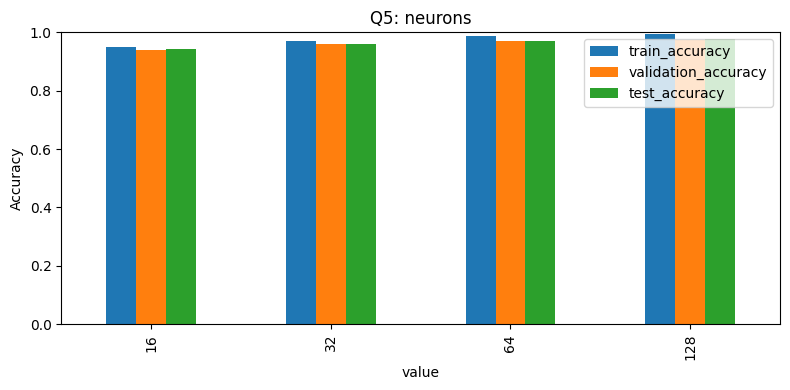

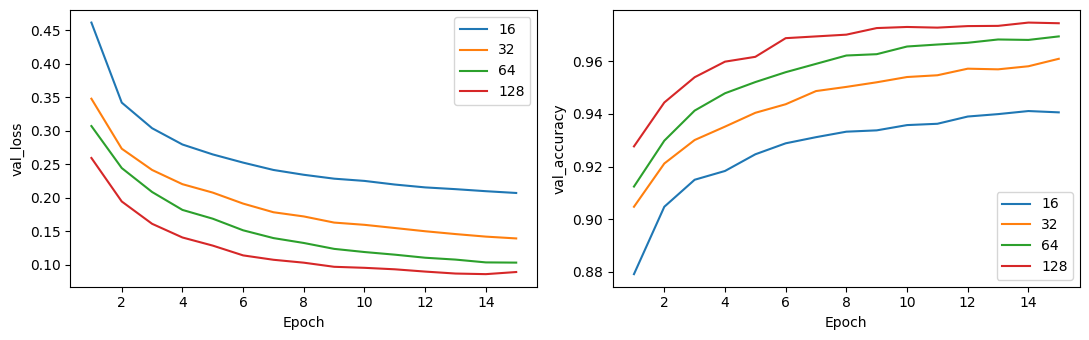

,group,value,width,learning_rate,optimizer,regularization,epochs,best_epoch,stopped_early,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
4,learning_rate,0.001,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718
5,learning_rate,0.01,64,0.010,Adam,none,9,6,True,0.044388,0.985438,0.108121,0.971417,0.110589,0.9707
6,learning_rate,0.1,64,0.100,Adam,none,5,2,True,0.306144,0.913500,0.346208,0.907750,0.326411,0.9118


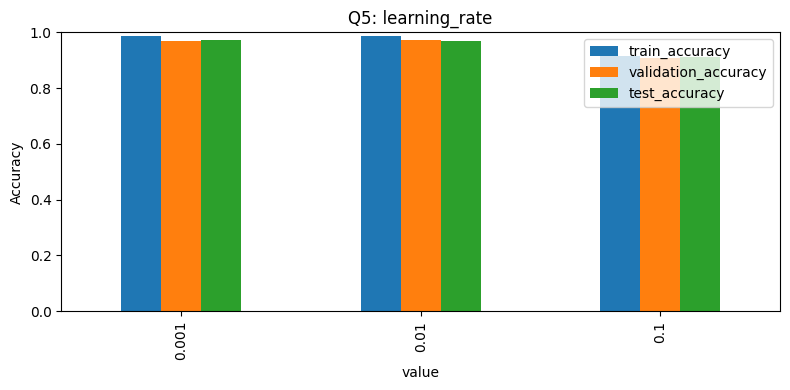

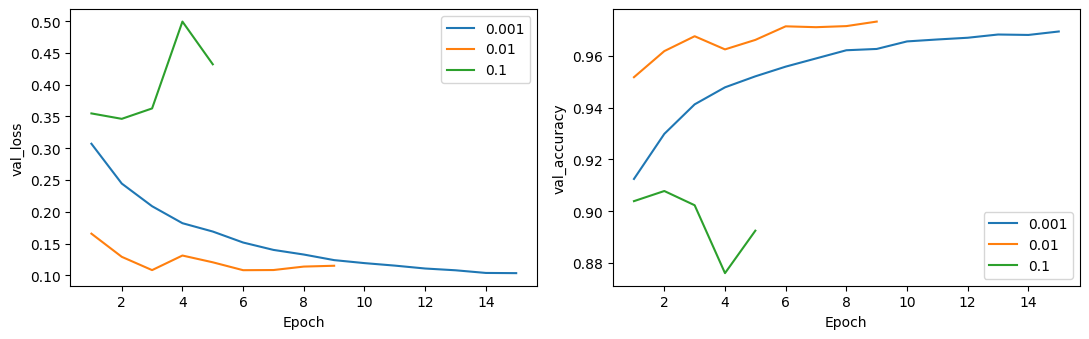

,group,value,width,learning_rate,optimizer,regularization,epochs,best_epoch,stopped_early,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
7,optimizer,SGD,64,0.001,SGD,none,15,15,False,0.340301,0.905083,0.345846,0.904083,0.325155,0.9096
8,optimizer,RMSprop,64,0.001,RMSprop,none,15,15,False,0.052799,0.985396,0.101198,0.970500,0.093506,0.9730
9,optimizer,Adam,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718


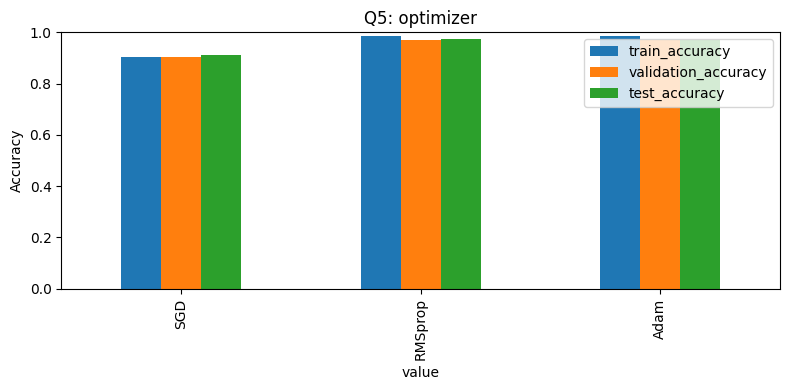

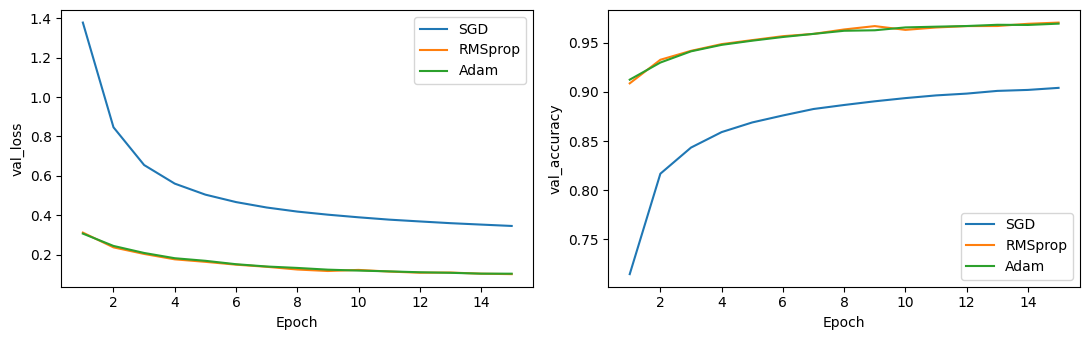

,group,value,width,learning_rate,optimizer,regularization,epochs,best_epoch,stopped_early,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
10,regularization,none,64,0.001,Adam,none,15,15,False,0.053025,0.985729,0.103469,0.969417,0.097282,0.9718
11,regularization,dropout,64,0.001,Adam,dropout,15,15,False,0.074079,0.979000,0.110455,0.967750,0.107796,0.9682
12,regularization,l2,64,0.001,Adam,l2,15,15,False,0.082819,0.984312,0.124976,0.970917,0.118805,0.9719
13,regularization,dropout+l2,64,0.001,Adam,dropout+l2,15,15,False,0.105269,0.977063,0.137417,0.967333,0.133005,0.9678


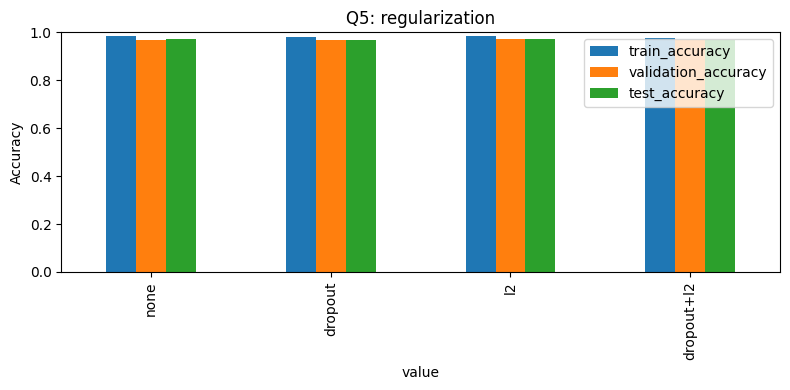

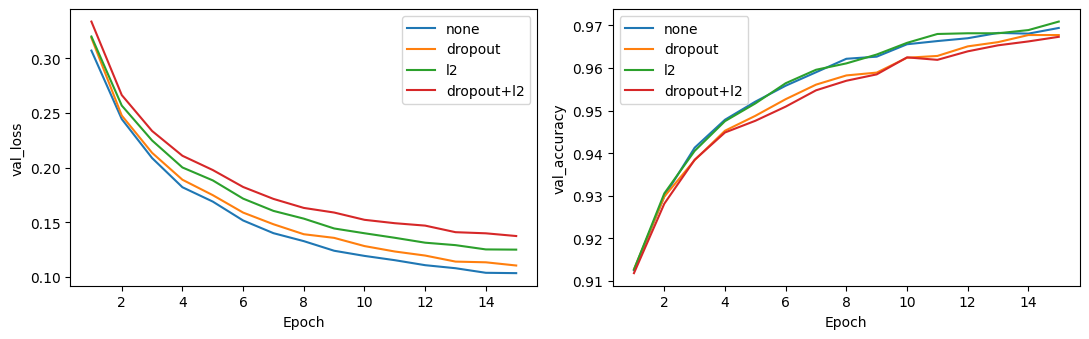

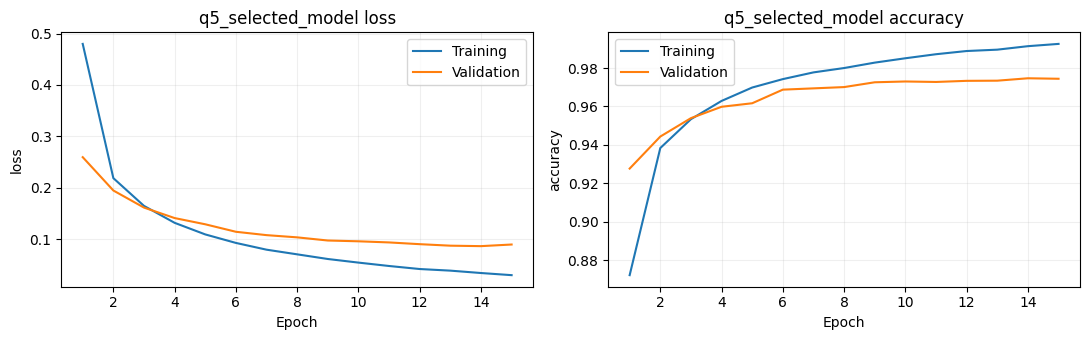

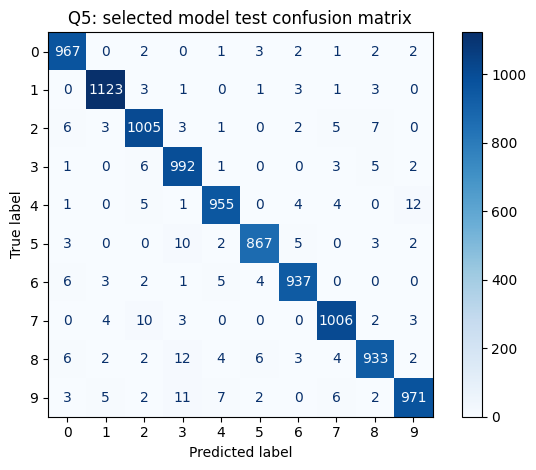

**Validation-selected configuration:** (128, 0.001, 'Adam', 'none'). Validation accuracy 0.9747, test accuracy 0.9756. Training ran 15 epochs and the minimum raw validation loss occurred at epoch 14. The epoch limit was reached; early stopping did not trigger for this configuration. 

,group,value,epochs,best_epoch,stopped_early
0,neurons,16,15,15,False
1,neurons,32,15,15,False
2,neurons,64,15,15,False
3,neurons,128,15,14,False
4,learning_rate,0.001,15,15,False
5,learning_rate,0.01,9,6,True
6,learning_rate,0.1,5,2,True
7,optimizer,SGD,15,15,False
8,optimizer,RMSprop,15,15,False
9,optimizer,Adam,15,15,False


In [6]:
(mx,my),(mx_test,my_test)=keras.datasets.mnist.load_data()
print('MNIST dimensions:',mx.shape,my.shape,mx_test.shape,my_test.shape)
mx=mx.astype('float32')/255; mx_test=mx_test.astype('float32')/255
mx_train,mx_val,my_train,my_val=train_test_split(mx,my,test_size=.2,stratify=my,random_state=SEED)
del mx
configs=[]
for width in [16,32,64,128]: configs.append(dict(group='neurons',value=str(width),width=width))
for lr in [.001,.01,.1]: configs.append(dict(group='learning_rate',value=str(lr),lr=lr))
for optimizer in ['SGD','RMSprop','Adam']: configs.append(dict(group='optimizer',value=optimizer,optimizer=optimizer))
for reg in ['none','dropout','l2','dropout+l2']: configs.append(dict(group='regularization',value=reg,reg=reg))
mnist_rows=[]; mnist_cache={}; mnist_histories={}; mnist_probabilities={}
for config in configs:
    width=config.get('width',64); lr=config.get('lr',.001)
    optimizer_name=config.get('optimizer','Adam'); reg=config.get('reg','none')
    key=(width,lr,optimizer_name,reg)
    if key not in mnist_cache:
        reset()
        penalty=keras.regularizers.l2(.0001) if 'l2' in reg else None
        layers=[keras.Input((28,28)),keras.layers.Flatten(),
                keras.layers.Dense(width,activation='relu',kernel_regularizer=penalty)]
        if 'dropout' in reg: layers.append(keras.layers.Dropout(.3))
        model=keras.Sequential(layers+[keras.layers.Dense(10,activation='softmax')],name='mnist')
        optimizer={'Adam':lambda:keras.optimizers.Adam(lr),
            'SGD':lambda:keras.optimizers.SGD(lr,momentum=.9),
            'RMSprop':lambda:keras.optimizers.RMSprop(lr)}[optimizer_name]()
        model.compile(optimizer=optimizer,loss='sparse_categorical_crossentropy',metrics=['accuracy'])
        print('Configuration:',key)
        hist,stop=fit(model,mx_train,my_train,mx_val,my_val,epochs=15,patience=3)
        scores={split:model.evaluate(dataset(x,y),verbose=0) for split,x,y in
                [('train',mx_train,my_train),('validation',mx_val,my_val),('test',mx_test,my_test)]}
        mnist_cache[key]=dict(width=width,learning_rate=lr,optimizer=optimizer_name,regularization=reg,
            epochs=len(hist.epoch),best_epoch=int(np.argmin(hist.history['val_loss']))+1,
            stopped_early=bool(stop.stopped_epoch>0),
            **{f'{split}_{metric}':float(score[i]) for split,score in scores.items()
               for i,metric in enumerate(['loss','accuracy'])})
        mnist_histories[key]=hist
        mnist_probabilities[key]=predict(model,mx_test)
    mnist_rows.append(dict(group=config['group'],value=config['value'],**mnist_cache[key]))
mnist_results=pd.DataFrame(mnist_rows); table(mnist_results,'q5_all_experiments')
for group in ['neurons','learning_rate','optimizer','regularization']:
    subset=mnist_results[mnist_results.group==group]
    table(subset,'q5_'+group)
    subset.plot(x='value',y=['train_accuracy','validation_accuracy','test_accuracy'],kind='bar',figsize=(8,4),ylim=(0,1))
    plt.ylabel('Accuracy'); plt.title('Q5: '+group); saveplot('q5_'+group+'_comparison')
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for _,row in subset.iterrows():
        key=(int(row.width),row.learning_rate,row.optimizer,row.regularization)
        hist=mnist_histories[key]
        for ax,metric in zip(axes,['val_loss','val_accuracy']):
            ax.plot(np.arange(1,len(hist.epoch)+1),hist.history[metric],label=row.value)
            ax.set(xlabel='Epoch',ylabel=metric)
    for ax in axes: ax.legend()
    saveplot('q5_'+group+'_validation_curves')
best_key=max(mnist_cache,key=lambda key:mnist_cache[key]['validation_accuracy'])
best=mnist_cache[best_key]
curves(mnist_histories[best_key],'q5_selected_model')
ConfusionMatrixDisplay.from_predictions(my_test,mnist_probabilities[best_key].argmax(axis=1),cmap='Blues')
plt.title('Q5: selected model test confusion matrix'); saveplot('q5_confusion')
display(Markdown(f'**Validation-selected configuration:** {best_key}. Validation accuracy '
    f'{best["validation_accuracy"]:.4f}, test accuracy {best["test_accuracy"]:.4f}. '
    f'Training ran {best["epochs"]} epochs and the minimum raw validation loss occurred at epoch {best["best_epoch"]}. '
    + ('Early stopping fired after three epochs without sufficient validation-loss improvement; best weights were restored. '
       if best['stopped_early'] else 'The epoch limit was reached; early stopping did not trigger for this configuration. ')))
stop_table=mnist_results[['group','value','epochs','best_epoch','stopped_early']]
table(stop_table,'q5_early_stopping')

### Q5 observations and conclusions
The tables and plots above contain the measured outcome for every required comparison. Greater width increases
capacity and parameter count; compare whether validation accuracy improves enough to justify it. Learning rate
0.001 takes smaller steps, 0.01 may converge faster, and 0.1 may oscillate or reach a worse solution; the measured
curves determine which occurred here. Adam and RMSprop adapt per-parameter steps, while SGD may need a
different rate or more epochs for a fair best-achievable-performance comparison.

Dropout and L2 may reduce overfitting, but they need not improve test accuracy with this dataset and epoch
budget. Compare inference-time train-validation accuracy gaps, not just training-time dropout accuracy.
Early stopping uses validation loss rather than the test set; the table explicitly distinguishes patience stops
from maximum-epoch termination. These one-seed, fixed-budget comparisons demonstrate effects rather than
establishing statistically significant rankings; repeated seeds and nested validation would strengthen conclusions.

In [7]:
# Numerical observations derived from this run, rather than assumed outcomes.
for group in ['neurons','learning_rate','optimizer','regularization']:
    subset=mnist_results[mnist_results.group==group]
    top=subset.loc[subset.validation_accuracy.idxmax()]
    display(Markdown(f'**{group}:** best validation accuracy is {top.validation_accuracy:.4f} '
        f'for {top.value}; its test accuracy is {top.test_accuracy:.4f} and inference-time '
        f'train-validation gap is {top.train_accuracy-top.validation_accuracy:.4f}.'))
summary={'q2':bc_metrics,'q3':cifar_rows,'q4':housing_rows,'q5_selected':best,
         'q5_unique_runs':len(mnist_cache)}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
assert len(logic_table)==16
assert len(mnist_results)==14 and len(mnist_cache)==11
assert all(np.isfinite(row['RMSE']) for row in housing_rows)
print('All five experiments completed. Tables, plots and summary saved in results/.')

**neurons:** best validation accuracy is 0.9747 for 128; its test accuracy is 0.9756 and inference-time train-validation gap is 0.0196.

**learning_rate:** best validation accuracy is 0.9714 for 0.01; its test accuracy is 0.9707 and inference-time train-validation gap is 0.0140.

**optimizer:** best validation accuracy is 0.9705 for RMSprop; its test accuracy is 0.9730 and inference-time train-validation gap is 0.0149.

**regularization:** best validation accuracy is 0.9709 for l2; its test accuracy is 0.9719 and inference-time train-validation gap is 0.0134.

All five experiments completed. Tables, plots and summary saved in results/.


## Overall conclusion and data provenance
Nonlinear hidden layers solve XOR; a single linear boundary cannot. Binary classification uses sigmoid/BCE,
multiclass classification uses softmax/categorical cross-entropy, and regression uses a linear output/MSE.
Scaling, leakage-free preprocessing, validation-guided selection and regularization are central to all experiments.
The preceding sections report the actual measured metrics and limitations for each dataset.

Sources: [Breast Cancer Wisconsin via scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html),
[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html),
[California Housing via scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html),
[MNIST via Keras](https://keras.io/api/datasets/mnist/).
This notebook addresses the provided assignment; GitHub delivery follows the user's request.

## Measured results and observations

These observations are generated from the saved execution results, with seed 42.

### Q1

AND, OR and multilayer XOR classify all four inputs correctly. Single-layer XOR fails, as required by its lack of linear separability.

### Q2

Test accuracy is 97.37%, malignant-class precision 1.0000, recall 0.9286, and F1 0.9630. The validation-loss curve flattens while training loss continues to fall, indicating mild late overfitting rather than underfitting. Early stopping limits it; L2 would be a useful next experiment.

### Q3

Baseline test accuracy is 50.33%; dropout test accuracy is 44.70%, a change of -5.63 percentage points. The inference-time training-validation gap changes from 0.0573 to 0.0170. Dropout therefore needs to be assessed from both the gap and held-out accuracy, rather than assumed to improve performance.
Here, dropout reduces both training and test accuracy, consistent with too much regularization or insufficient training for this capacity. Prefer the baseline by its lower validation loss; consider weaker dropout or a longer validation-controlled budget in a future experiment.
The most frequent directed confusion for baseline is **airplane → ship**, with 230 test images.
The most frequent directed confusion for dropout is **bird → deer**, with 245 test images.

### Q4

Choose **SGD** for further testing because it has the lower validation MSE (0.2988). Its test MAE is 0.3786, MSE 0.2985, RMSE 0.5464 and R² 0.7722. RMSE corresponds to approximately $54,637. The actual-versus-predicted plot reveals residual spread and the dataset ceiling; the notebook discusses fitting behavior using the training/validation curves.

The alternative, Adam, has test RMSE 0.5396. The validation difference is small; repeated splits would be needed to establish a reliable optimizer ranking. Model selection remains based on validation performance even when the test ranking differs.

### Q5

- **neurons:** validation-selected setting 128; validation accuracy 97.47%, test accuracy 97.56%.
- **learning_rate:** validation-selected setting 0.01; validation accuracy 97.14%, test accuracy 97.07%.
- **optimizer:** validation-selected setting RMSprop; validation accuracy 97.05%, test accuracy 97.30%.
- **regularization:** validation-selected setting l2; validation accuracy 97.09%, test accuracy 97.19%.

Increasing hidden width from 16 to 128 changes validation accuracy from 94.06% to 97.47%. Wider layers add parameters and can model more digit variation, at greater computation cost.

Increasing the rate from 0.001 to 0.1 changes validation accuracy from 96.94% to 90.78%. The larger steps hurt the final solution in this run.

- **none:** training-validation accuracy gap 0.0163; test accuracy 97.18%.
- **dropout:** training-validation accuracy gap 0.0112; test accuracy 96.82%.
- **l2:** training-validation accuracy gap 0.0134; test accuracy 97.19%.
- **dropout+l2:** training-validation accuracy gap 0.0097; test accuracy 96.78%.

Compared with no regularization, **dropout** reduces the accuracy gap by 0.0051 and changes validation accuracy by -0.17 percentage points. The smaller capacity or penalty does not improve validation accuracy within this budget.

Compared with no regularization, **l2** reduces the accuracy gap by 0.0029 and changes validation accuracy by +0.15 percentage points. This improves validation performance in this run.

Compared with no regularization, **dropout+l2** reduces the accuracy gap by 0.0066 and changes validation accuracy by -0.21 percentage points. The smaller capacity or penalty does not improve validation accuracy within this budget.

Early stopping triggered in 2 of 11 unique runs; 9 reached the 15-epoch cap. The per-run stopping table records the epoch count and best epoch. Test scores are descriptive and were not used to choose settings.

These results use a single seed and a finite budget. Repeated seeds and further validation are needed before treating close differences as meaningful.
